# Minor Project: California Housing Prices Prediction using Gradient Boosting

**Student Name**: Shalini
**Course**: 5th Semester AIML, GEC Hassan.
**Dataset Name**: California Housing Prices
**Kaggle Link**:https://www.kaggle.com/datasets/camnugent/california-housing-prices

### Project Objective & Problem Statement
Objective: Build an end-to-end regression machine learning pipeline utilizing ensemble boosting techniques to predict median house values across California districts.
Why it matters: Accurate property valuation helps real estate investors, urban planners, and buyers understand regional housing trends and affordability based on income, location, and room statistics.

In [45]:
# Cell 1: Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [46]:
# Cell 2: Load the dataset
df = pd.read_csv('/content/housing.csv')

In [47]:
# Cell 3: Inspect dataset head
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [48]:
# Cell 4: Inspect dataset tail
df.tail()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND


In [49]:
# Cell 5: Statistical summary
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [50]:
# Cell 4: Inspect data types, missing values, and duplicates
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [51]:
# Cell 5: Missing values
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [52]:
#Cell 6: Handle missing values by filling them with the column median
df['total_bedrooms'] = df['total_bedrooms'].fillna(df['total_bedrooms'].median())

# Verify no nulls remain
print("Remaining missing values:", df.isnull().sum().sum())

Remaining missing values: 0


In [53]:
# Cell 7: Duplicates
df.duplicated().sum()

np.int64(0)

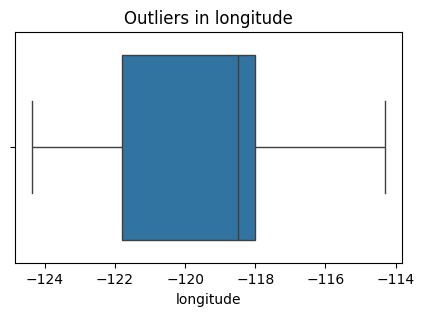

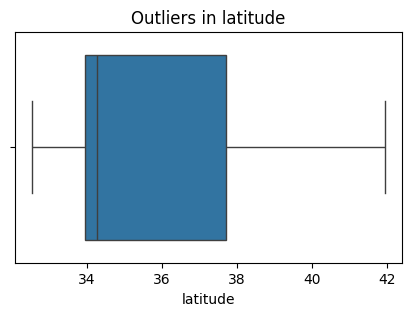

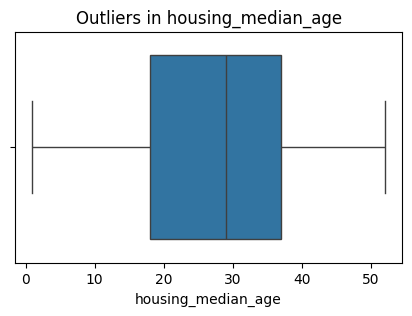

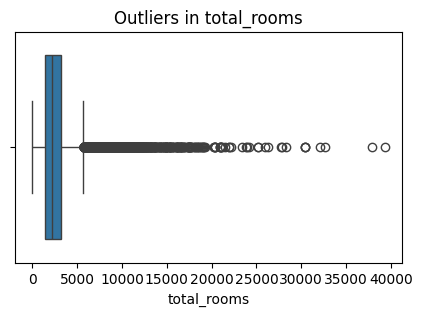

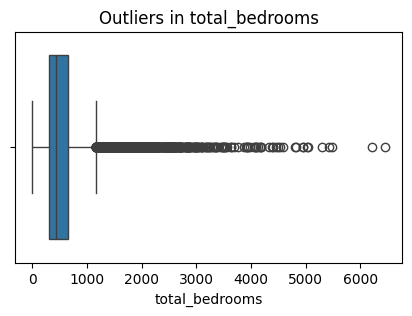

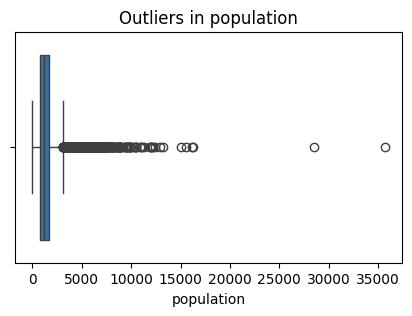

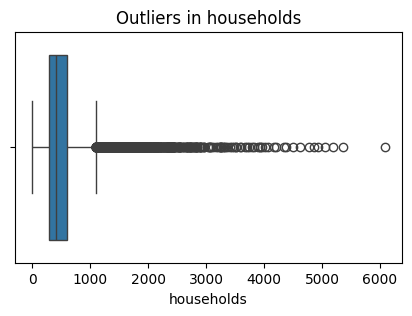

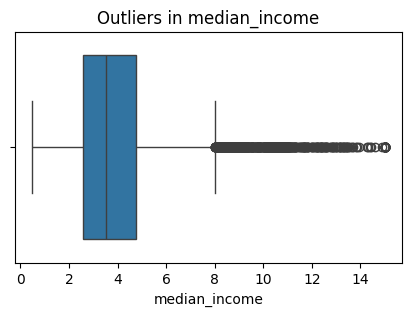

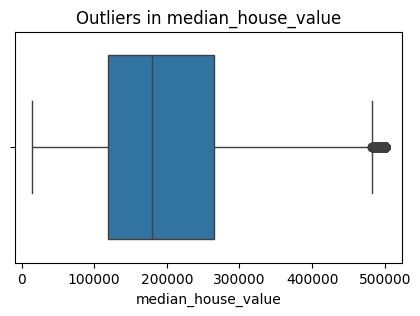

In [54]:
# Cell 8: Visualize outliers using Box Plots
for col in df.select_dtypes(include=[np.number]).columns:
  plt.figure(figsize=(5, 3))
  sns.boxplot(x=df[col])
  plt.title(f'Outliers in {col}')
  plt.show()

Observation: The box plots reveal the presence of extreme data points (outliers) beyond the whiskers across several numerical features (such as total_rooms, population, and households), justifying the application of outlier treatment via clipping.

In [55]:
# Cell 9: # Outlier Treatment using the Interquartile Range (IQR) and Clipping method

# 1. Select only numerical columns (excluding the target variable if needed)
num_cols = df.select_dtypes(include=[np.number]).columns

# 2. Loop through each numerical column to find and cap outliers
for col in num_cols:
    # Calculate 25th (Q1) and 75th (Q3) percentiles
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    # Calculate Interquartile Range
    IQR = Q3 - Q1

    # Define acceptable lower and upper bounds
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Clip/cap the values so they stay strictly within the bounds
    df[col] = df[col].clip(lower=lower_bound, upper=upper_bound)

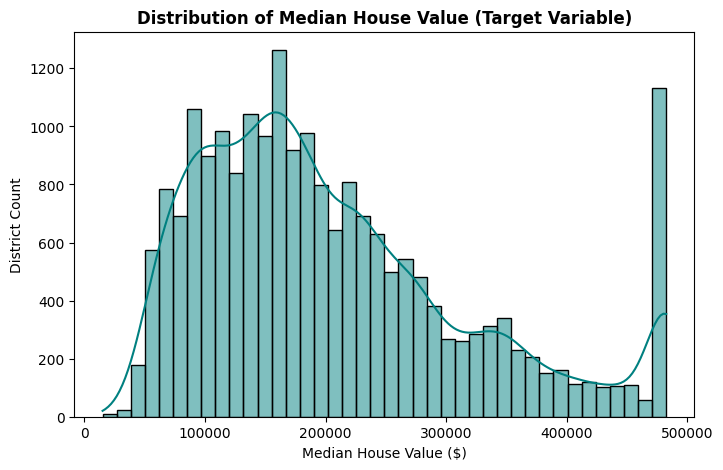

In [56]:
# Cell 10: Target Distribution Plot
plt.figure(figsize=(8, 5))
sns.histplot(df['median_house_value'], kde=True, color='teal', bins=40)
plt.title('Distribution of Median House Value (Target Variable)', fontsize=12, fontweight='bold')
plt.xlabel('Median House Value ($)', fontsize=10)
plt.ylabel('District Count', fontsize=10)
plt.show()

Observation: The target distribution chart reveals a right-skewed pattern with a dense clustering of district house values and an artificial upper cap at $500,000.

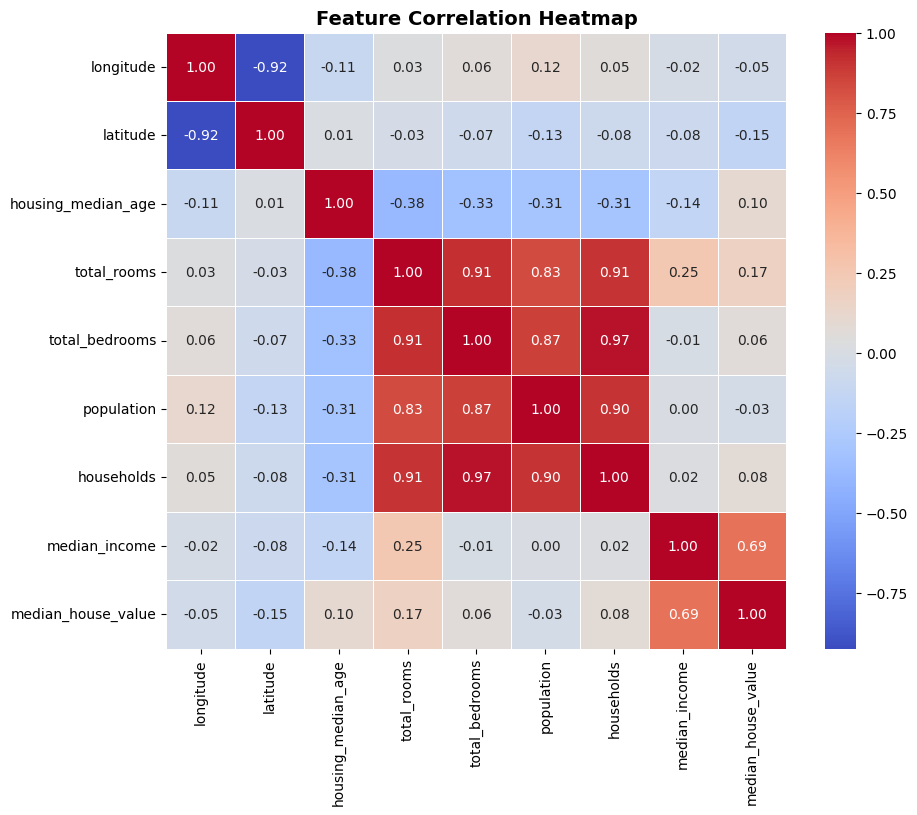

In [57]:
# Cell 11: Correlation Heatmap
plt.figure(figsize=(10, 8))
correlation_matrix = df.select_dtypes(include=[np.number]).corr()

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Feature Correlation Heatmap', fontsize=14, fontweight='bold')
plt.show()

Observation: The correlation heatmap displays the linear dependencies among numerical features, helping identify which variables share strong positive or negative relationships with the target variable.

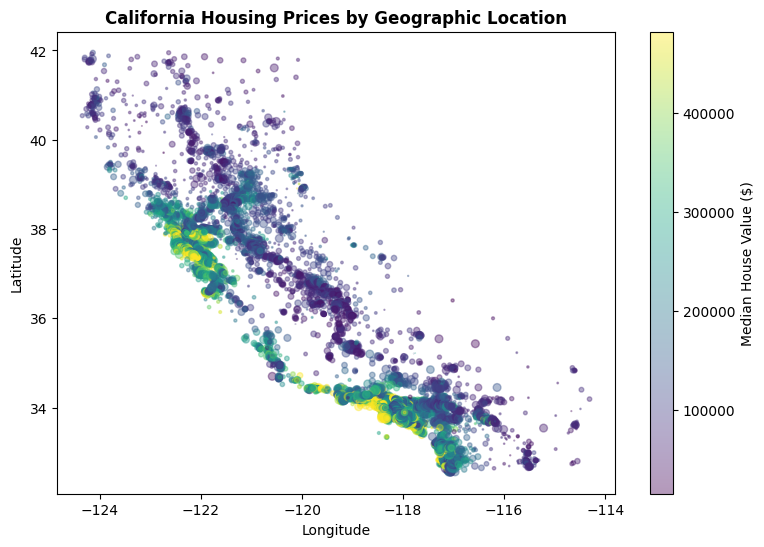

In [58]:
# Cell 12: Geographical Price Scatter Plot
plt.figure(figsize=(9, 6))
scatter = plt.scatter(df['longitude'], df['latitude'], c=df['median_house_value'], cmap='viridis',alpha=0.4, s=df['population']/100)
plt.colorbar(scatter, label='Median House Value ($)')
plt.title('California Housing Prices by Geographic Location', fontsize=12, fontweight='bold')
plt.xlabel('Longitude', fontsize=10)
plt.ylabel('Latitude', fontsize=10)
plt.show()

Observation: The geographical scatter plot clearly illustrates that higher-value properties cluster heavily along coastal regions and major metropolitan hubs, whereas inland districts consistently record lower median house values.

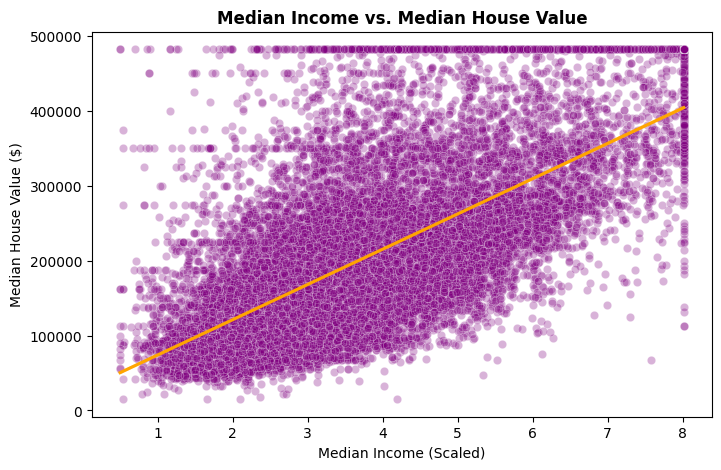

In [59]:
# Cell 13: Income vs House Value Relationship
plt.figure(figsize=(8, 5))
sns.scatterplot(x='median_income', y='median_house_value', data=df, alpha=0.3, color='purple')
sns.regplot(x='median_income', y='median_house_value', data=df, scatter=False, color='orange')
plt.title('Median Income vs. Median House Value', fontsize=12, fontweight='bold')
plt.xlabel('Median Income (Scaled)', fontsize=10)
plt.ylabel('Median House Value ($)', fontsize=10)
plt.show()

Observation: The scatter plot and regression line demonstrate a strong positive linear relationship between median income and house value, indicating that higher income districts strongly correlate with higher property prices, though an upper pricing cap exists at $500,000.

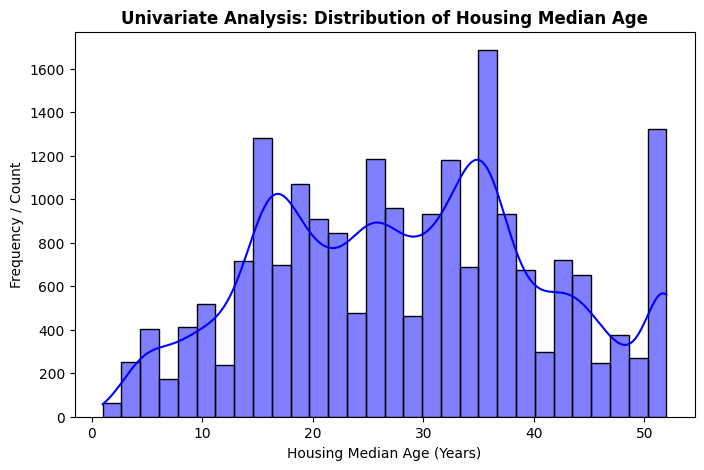

In [60]:
# Cell 14: Univariate Analysis
plt.figure(figsize=(8, 5))
sns.histplot(df['housing_median_age'], kde=True, color='blue', bins=30)
plt.title('Univariate Analysis: Distribution of Housing Median Age', fontsize=12, fontweight='bold')
plt.xlabel('Housing Median Age (Years)', fontsize=10)
plt.ylabel('Frequency / Count', fontsize=10)
plt.show()

Observation: The univariate distribution of housing median age shows a relatively even spread across various building ages, with visible peaks at specific age brackets and an upper boundary cap at 52 years.

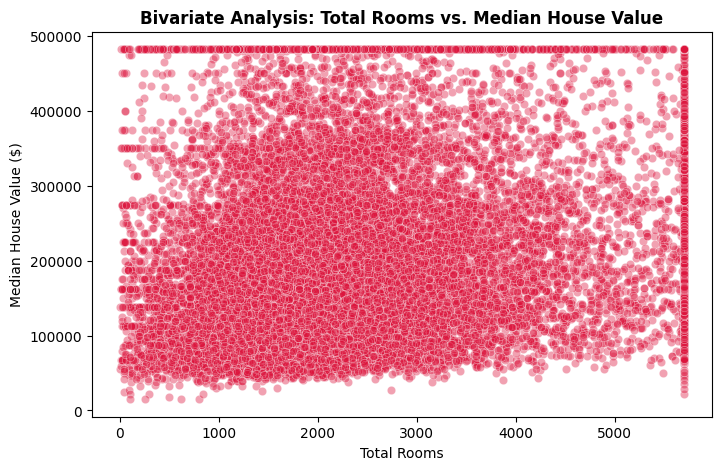

In [61]:
# Cell 15: Bivariate Analysis (Total Rooms vs. Median House Value)
plt.figure(figsize=(8, 5))
sns.scatterplot(x='total_rooms', y='median_house_value', data=df, alpha=0.4, color='crimson')
plt.title('Bivariate Analysis: Total Rooms vs. Median House Value', fontsize=12, fontweight='bold')
plt.xlabel('Total Rooms', fontsize=10)
plt.ylabel('Median House Value ($)', fontsize=10)
plt.show()

Observation: The bivariate scatter plot indicates that districts with varying total room counts span a wide distribution of house values, with high-value properties appearing across both smaller and larger room counts.

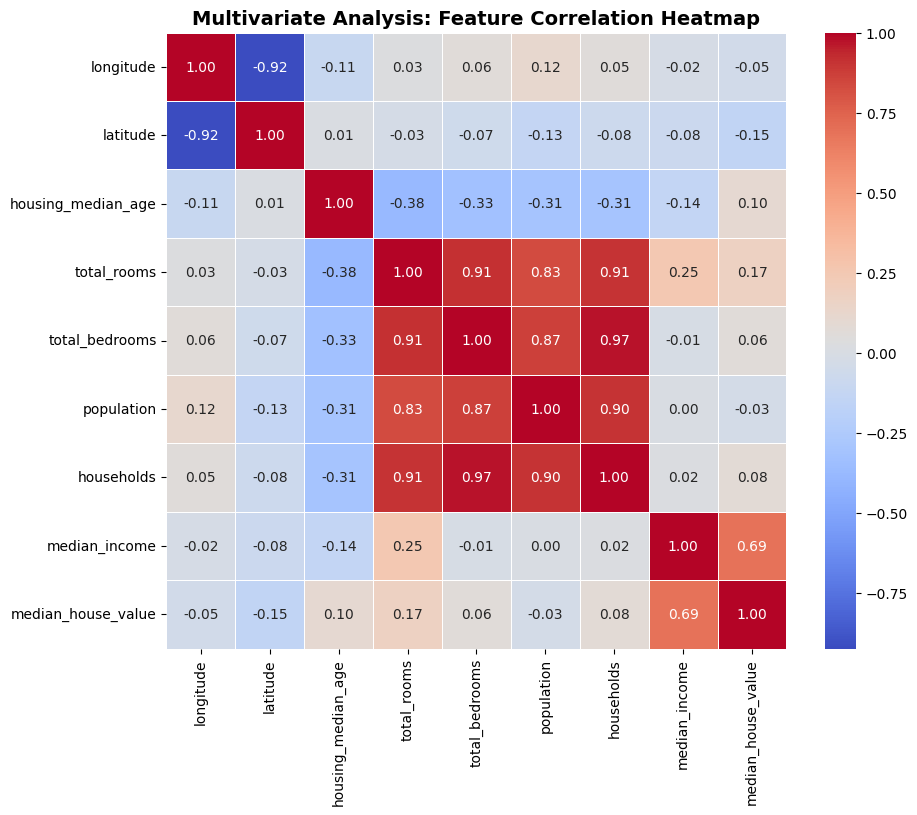

In [62]:
# Cell 16: Multivariate Analysis using a Correlation Heatmap
plt.figure(figsize=(10, 8))

# Calculate correlation matrix for all numerical columns
corr_matrix = df.select_dtypes(include=[np.number]).corr()

# Plot the heatmap
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, cbar=True)
plt.title('Multivariate Analysis: Feature Correlation Heatmap', fontsize=14, fontweight='bold')
plt.show()

Observation: The multivariate correlation heatmap displays the correlation coefficients among all numerical variables simultaneously, clearly highlighting key interactions such as the strong positive relationship between median income and median house value.

In [63]:
# Cell 17: One-Hot Encoding for categorical variables
cat_cols = df.select_dtypes(include=['object']).columns
print("Categorical columns found:", list(cat_cols))

if len(cat_cols) > 0:
    df = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)
    print("Encoding complete. Updated DataFrame shape:", df.shape)
else:
    print("No categorical columns to encode.")

Categorical columns found: ['ocean_proximity']
Encoding complete. Updated DataFrame shape: (20640, 13)


Observation :Categorical attributes such as ocean proximity were converted into numerical indicator features using one-hot encoding to ensure compatibility with numerical boosting algorithms.

In [64]:
# Cell 18: Separate feature matrix (X) and target vector (y), then split 80/20
from sklearn.model_selection import train_test_split

X = df.drop('median_house_value', axis=1)
y = df['median_house_value']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

Training features shape: (16512, 12)
Testing features shape: (4128, 12)


In [65]:
# Cell 19: Initialize and train the Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor

boosting_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    random_state=42
)

boosting_model.fit(X_train, y_train)

GradientBoostingRegressor(max_depth=4, random_state=42)

In [66]:
# Cell 20: Evaluate model performance on test data
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

y_pred = boosting_model.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("--- Model Evaluation Results ---")
print(f"R² Score: {r2:.4f}")
print(f"Mean Absolute Error (MAE): ${mae:.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:.2f}")

--- Model Evaluation Results ---
R² Score: 0.7934
Mean Absolute Error (MAE): $34898.06
Root Mean Squared Error (RMSE): $51111.44


In [67]:
y_pred = boosting_model.predict(X_test)
print(y_pred)

[ 48150.15080274  74536.54752175 370934.63833255 ... 465977.59783979
  88952.59567499 197517.54397062]


In [68]:
print("Training accuracy:", boosting_model.score(X_train, y_train))
print("Testing accuracy:", boosting_model.score(X_test, y_test))

Training accuracy: 0.8301189463444968
Testing accuracy: 0.7933826706327611


In [69]:
# Hyperparameter Tuning using GridSearchCV
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingRegressor

# 1. Initialize the base model
gbr = GradientBoostingRegressor(random_state=42)

# 2. Define the dictionary of hyperparameters to test
param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.05, 0.1, 0.2],
    'max_depth': [3, 4, 5]
}

# 3. Setup GridSearchCV with 3-fold cross-validation
grid_search = GridSearchCV(estimator=gbr,param_grid=param_grid,
    cv=3,                  # Number of cross-validation folds
    scoring='r2',          # Evaluation metric to optimize
    n_jobs=-1              # Use all available CPU cores for faster training
)

# 4. Fit the grid search to the training data
print("Running Grid Search for optimal hyperparameters...")
grid_search.fit(X_train, y_train)

# 5. Output the results
print("\n--- Tuning Results ---")
print("Best Hyperparameters Found:", grid_search.best_params_)
print(f"Best Cross-Validation R² Score: {grid_search.best_score_:.4f}")

# 6. Assign the best optimized model for final testing
best_boosting_model = grid_search.best_estimator_

Running Grid Search for optimal hyperparameters...

--- Tuning Results ---
Best Hyperparameters Found: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}
Best Cross-Validation R² Score: 0.8239


In [70]:
print("Training Accuracy Score:", grid_search.score(X_train, y_train))
print("Testing Accuracy Score:", grid_search.score(X_test, y_test))

Training Accuracy Score: 0.8939120678397767
Testing Accuracy Score: 0.8217576315975914
